# Chapitre 7 - Cours 5 : pourquoi sharder ? Avantages, inconvénients et multi-location

Les cours 1 à 4 ont répondu à la question « comment sharder ? ». Ce dernier cours prend
du recul et pose deux questions que la 2e édition du livre traite en ouverture du
chapitre : **faut-il sharder**, et à quel prix ? Et le sharding peut-il servir à autre
chose qu'à passer à l'échelle, en particulier à **isoler les clients** d'un logiciel
multi-locataire (SaaS) ? Il couvre les sections *Pros and Cons of Sharding* et
*Sharding for Multitenancy*.

**Plan.**

1. Quand une seule machine suffit : ordres de grandeur.
2. Ce que le sharding apporte : des écritures qui passent à l'échelle.
3. Le prix : clé de partitionnement et transactions multi-shards.
4. Sharder à l'intérieur d'une machine : un processus par cœur.
5. Multi-location : un locataire, un shard ?
6. Isolation : voisin bruyant, permissions et architecture cellulaire.
7. Sauvegarde, effacement, résidence et migrations progressives.
8. Les difficultés : locataires qui grandissent, géants et requêtes transverses.

In [1]:
import sqlite3
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia import partitioning_tenants as T
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")      # 1234567 -> « 1 234 567 »

## 1. Quand une seule machine suffit (section *Pros and Cons of Sharding*)

**Le problème.** Le sharding est la principale technique de **mise à l'échelle
horizontale** (*scale-out*) : au lieu d'acheter une machine plus grosse, on répartit les
données et les écritures sur plusieurs machines plus modestes, chacune responsable d'une
part à peu près égale. Mais le livre insiste sur un point souvent oublié : c'est une
solution **lourde**, qui ne se justifie qu'à grande échelle. La réplication, elle, est
utile à toute taille (tolérance aux pannes, lectures locales) ; le sharding ajoute de la
complexité dont on se passe volontiers tant qu'une seule machine tient la charge.

Or « une seule machine » est une quantité qui a beaucoup grandi. Un serveur haut de gamme
actuel compte des centaines de cœurs, plusieurs téraoctets de mémoire et des dizaines,
voire une centaine de téraoctets de SSD NVMe. Comparons ces limites à quelques charges
typiques (ordres de grandeur indicatifs, à remplacer par vos chiffres), puis calculons
combien d'années une charge qui croît de $g$ % par an met à dépasser la machine :
$t = \ln(C / V_0) / \ln(1 + g)$.

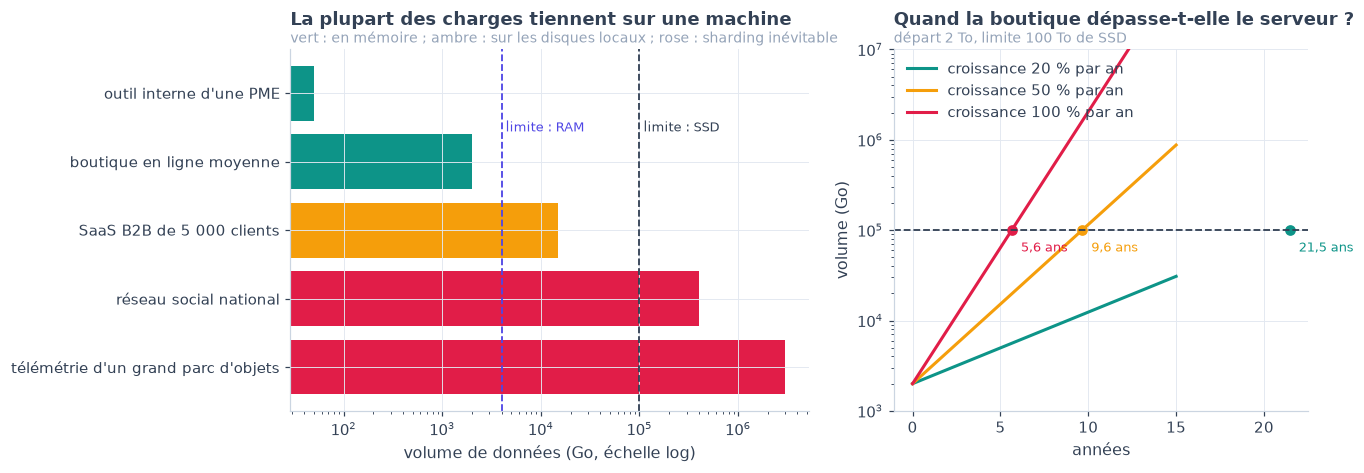

In [2]:
charges = pd.DataFrame({
    "charge": ["outil interne d'une PME", "boutique en ligne moyenne", "SaaS B2B de 5 000 clients",
               "réseau social national", "télémétrie d'un grand parc d'objets"],
    "donnees_Go": [50, 2_000, 15_000, 400_000, 3_000_000],
})
LIM_RAM, LIM_DISQUE = 4_000, 100_000          # Go : mémoire et SSD d'un gros serveur

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
cols = [TEAL if v < LIM_RAM else (AMBER if v < LIM_DISQUE else ROSE) for v in charges.donnees_Go]
ax1.barh(charges.charge, charges.donnees_Go, color=cols)
ax1.set_xscale("log")
ax1.axvline(LIM_RAM, color=INDIGO, ls="--", lw=1.2)
ax1.axvline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax1.text(LIM_RAM * 1.1, 0.5, "limite : RAM", color=INDIGO, fontsize=8.5, va="center")
ax1.text(LIM_DISQUE * 1.1, 0.5, "limite : SSD", color=SLATE, fontsize=8.5, va="center")
ax1.invert_yaxis()
ax1.set_xlabel("volume de données (Go, échelle log)")
ax1.set_title("La plupart des charges tiennent sur une machine")
subtitle(ax1, "vert : en mémoire ; ambre : sur les disques locaux ; rose : sharding inévitable")

V0 = 2_000
for g, c in [(0.2, TEAL), (0.5, AMBER), (1.0, ROSE)]:
    years = np.arange(0, 16)
    ax2.plot(years, V0 * (1 + g) ** years, color=c, label=f"croissance {g:.0%} par an".replace("%", " %"))
    t_cross = np.log(LIM_DISQUE / V0) / np.log(1 + g)
    ax2.plot([t_cross], [LIM_DISQUE], "o", color=c)
    ax2.annotate(f"{t_cross:.1f} ans".replace(".", ","), (t_cross, LIM_DISQUE), (6, -14),
                 textcoords="offset points", fontsize=8.5, color=c)
ax2.axhline(LIM_DISQUE, color=SLATE, ls="--", lw=1.2)
ax2.set_yscale("log")
ax2.set_ylim(1e3, 1e7)
ax2.set_xlabel("années")
ax2.set_ylabel("volume (Go)")
ax2.set_title("Quand la boutique dépasse-t-elle le serveur ?")
subtitle(ax2, "départ 2 To, limite 100 To de SSD")
ax2.legend(loc="upper left")
finish(fig)
plt.show()

Avec 2 To aujourd'hui, une boutique qui croît de 20 % par an dispose de plus de vingt
ans de marge ; même à 50 % par an, il lui reste presque une décennie. Le livre en tire
une recommandation nette : tant que le volume et le **débit d'écriture** tiennent sur un
nœud, mieux vaut rester sur une base à un seul shard (répliquée pour la tolérance aux
pannes) et garder la simplicité. Ce raisonnement est volontairement optimiste : il ne
tient compte ni du débit d'écriture (souvent la vraie limite, section suivante), ni du
temps de reconstruction d'un nœud de 100 To après une panne, qui peut lui aussi pousser à
découper plus tôt.

> **À retenir.** Le sharding se justifie quand les données ou les écritures dépassent
> ce qu'un nœud peut porter. Une machine actuelle porte beaucoup : vérifiez les ordres de
> grandeur avant de payer la complexité du sharding.